# 10 · ResNet50 (final phase)
**Owner:** Pihu Pandey (230953134)

ImageNet ResNet50 → global average pooling (2,048) → head.

Final protocol: brain-cropped images, leak-free split (07), same metrics. Steps: (1) grid search on the validation split with seed 42, (2) the chosen configuration trained with 3 seeds, scored once on the test split, (3) fine-tuning of the last convolutional block from the stage-1 head, (4) Grad-CAM.

In [1]:
%matplotlib inline
import os, sys
os.environ.setdefault("KERAS_BACKEND", "torch")   # Keras 3 backend used for our runs (CPU); "tensorflow" also works
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))        # make the project's src/ package importable

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from IPython.display import Image, display
from src import config, data_pipeline as dp, models, features, training

keras.utils.set_random_seed(config.SEED)
print("Keras", keras.__version__, "| backend:", keras.backend.backend())
from src import experiments as E, evaluation as ev, finetune as F, gradcam as G
RERUN = False    # True = retrain everything here; False = load the saved runs produced by the same code
                 # (scripts/run_heads.py, scripts/run_finetune.py), which take hours on a CPU

Keras 3.15.1 | backend: torch


## Inputs

In [2]:
m = E.manifest_for("final")
X = E.cnn_features("resnet50", "final")      # frozen ImageNet pooled features
print(X.shape, "| class weights", E.class_weight(m))

(7013, 2048) | class weights {0: 2.0855899419729207, 1: 0.6576700213479719}


## 1. Hyper-parameter search (validation split only)

In [3]:
grid_csv = config.RESULTS_DIR / "final" / "grid_resnet50.csv"
if RERUN:
    cfg, grid = E.grid_search("resnet50", X, m, E.HEAD_GRID)
else:
    grid = pd.read_csv(grid_csv)
    cfg = json.loads((config.RESULTS_DIR / "final" / "chosen_heads.json").read_text())["resnet50"]
print("chosen:", cfg)
grid

chosen: {'lr': 0.001, 'units': 128, 'dropout': 0.5}


,lr,units,dropout,val_balanced_accuracy,val_auc,val_loss,best_epoch
0,0.0010,128,0.5,0.9765,0.9982,0.048729,8
1,0.0003,128,0.5,0.9759,0.9983,0.047790,9
2,0.0003,256,0.3,0.9725,0.9983,0.046121,7
3,0.0010,256,0.5,0.9707,0.9982,0.048036,7
4,0.0003,128,0.3,0.9701,0.9976,0.055419,7
5,0.0010,256,0.3,0.9673,0.9982,0.050548,4
6,0.0003,256,0.5,0.9668,0.9980,0.052000,7
7,0.0010,128,0.3,0.9646,0.9978,0.059952,4


## 2. Chosen configuration, 3 seeds (frozen backbone)

In [4]:
variant = "frozen"
recs = E.run_seeds("resnet50", variant, "final", X, m, cfg) if RERUN else E.load_runs("final", "resnet50", variant)
pd.DataFrame({r["seed"]: {**{f"val_{k}": r["val_metrics"][k] for k in ["balanced_accuracy", "roc_auc"]},
                          **{f"test_{k}": r["test_metrics"][k] for k in ["accuracy", "recall", "specificity", "f1", "roc_auc"]},
                          "best_epoch": r["best_epoch"], "trainable_params": r["trainable_params"]} for r in recs}).T

,val_balanced_accuracy,val_roc_auc,test_accuracy,test_recall,test_specificity,test_f1,test_roc_auc,best_epoch,trainable_params
2026,0.9666,0.9984,0.9790,0.9903,0.9434,0.9862,0.9974,5.0,262530.0
42,0.9765,0.9982,0.9815,0.9886,0.9589,0.9878,0.9973,8.0,262530.0
7,0.9751,0.9986,0.9765,0.9829,0.9563,0.9845,0.9970,4.0,262530.0


In [5]:
summary = E.summarise(recs)
pd.DataFrame(summary).drop(columns="n_seeds").T.round(4)

,mean,std
accuracy,0.9790,0.0025
precision,0.9851,0.0025
recall,0.9873,0.0039
specificity,0.9529,0.0083
f1,0.9862,0.0017
balanced_accuracy,0.9700,0.0035
roc_auc,0.9972,0.0002
FN,15.6667,4.7258
FP,18.3333,3.2146


## 3. Fine-tuning the last block (stage 2)
Unfrozen: the `conv5` stage (3 bottleneck blocks, 14.96 M weights); BatchNorm layers stay frozen in inference mode. Adam, learning rate 1e-5, ≤ 12 epochs, early stopping on validation loss (patience 3), class weights; every epoch each training image is shown as one of three cached views (original or one of two random augmentations).

In [6]:
ft = E.load_runs("final", "resnet50", "finetuned")      # produced by scripts/run_finetune.py (same code: src/finetune.py)
pd.DataFrame({r["seed"]: {**{f"val_{k}": r["val_metrics"][k] for k in ["balanced_accuracy", "roc_auc"]},
                         **{f"test_{k}": r["test_metrics"][k] for k in ["accuracy", "recall", "specificity", "f1", "roc_auc"]},
                         "epochs_run": r["epochs_run"], "best_epoch": r["best_epoch"],
                         "minutes": round(r["train_seconds"] / 60, 1), "trainable_params": r["trainable_params"]} for r in ft}).T

,val_balanced_accuracy,val_roc_auc,test_accuracy,test_recall,test_specificity,test_f1,test_roc_auc,epochs_run,best_epoch,minutes,trainable_params
2026,0.9790,0.9984,0.9852,0.9878,0.9769,0.9902,0.9974,6.0,3.0,20.5,15216002.0
42,0.9796,0.9982,0.9840,0.9886,0.9692,0.9894,0.9974,5.0,2.0,19.3,15216002.0
7,0.9799,0.9981,0.9772,0.9797,0.9692,0.9849,0.9975,5.0,2.0,17.9,15216002.0


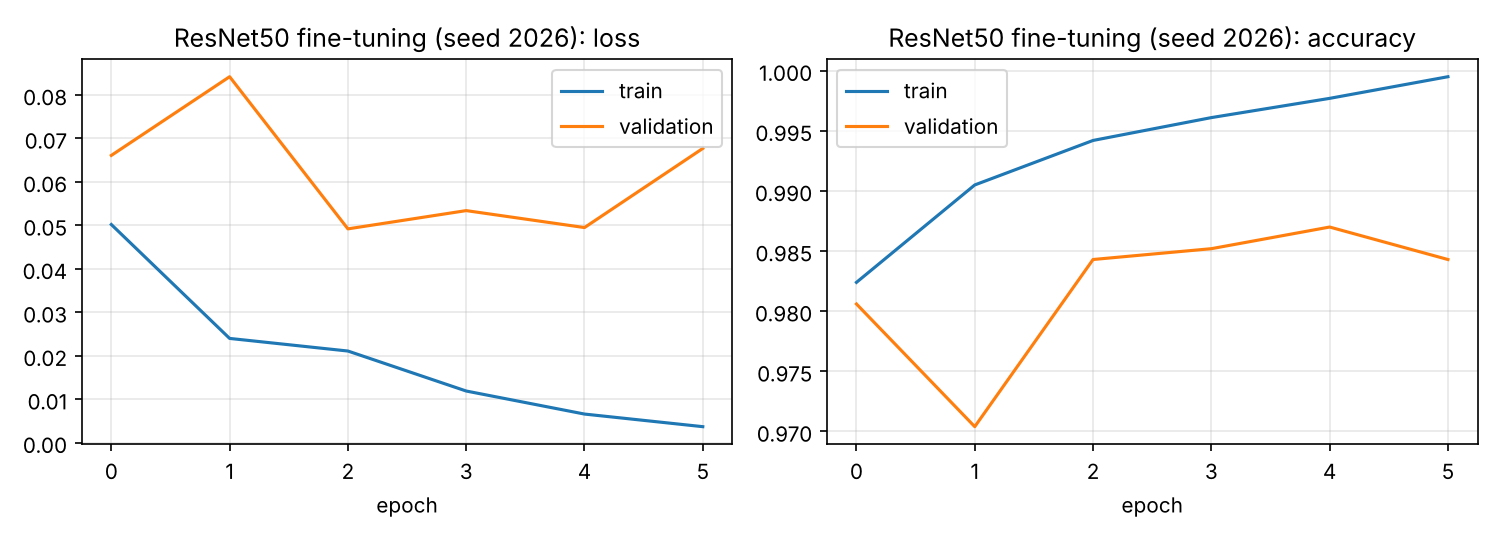

In [7]:
h = ft[0]["history"]
training.plot_history(h, "ResNet50 fine-tuning (seed {})".format(ft[0]["seed"]),
                      config.FIG_DIR / "final_resnet50_finetune_curves.png")
display(Image(str(config.FIG_DIR / "final_resnet50_finetune_curves.png"), width=700))

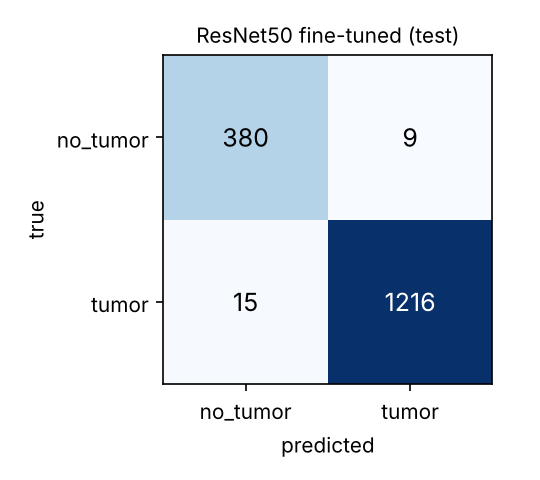

In [8]:
cm = ft[0]["test_metrics"]["confusion_matrix"]
training.plot_confusion(cm, "ResNet50 fine-tuned (test)", config.FIG_DIR / "final_resnet50_confusion.png")
display(Image(str(config.FIG_DIR / "final_resnet50_confusion.png"), width=300))

## 4. Grad-CAM on test images (fine-tuned model, seed 42)

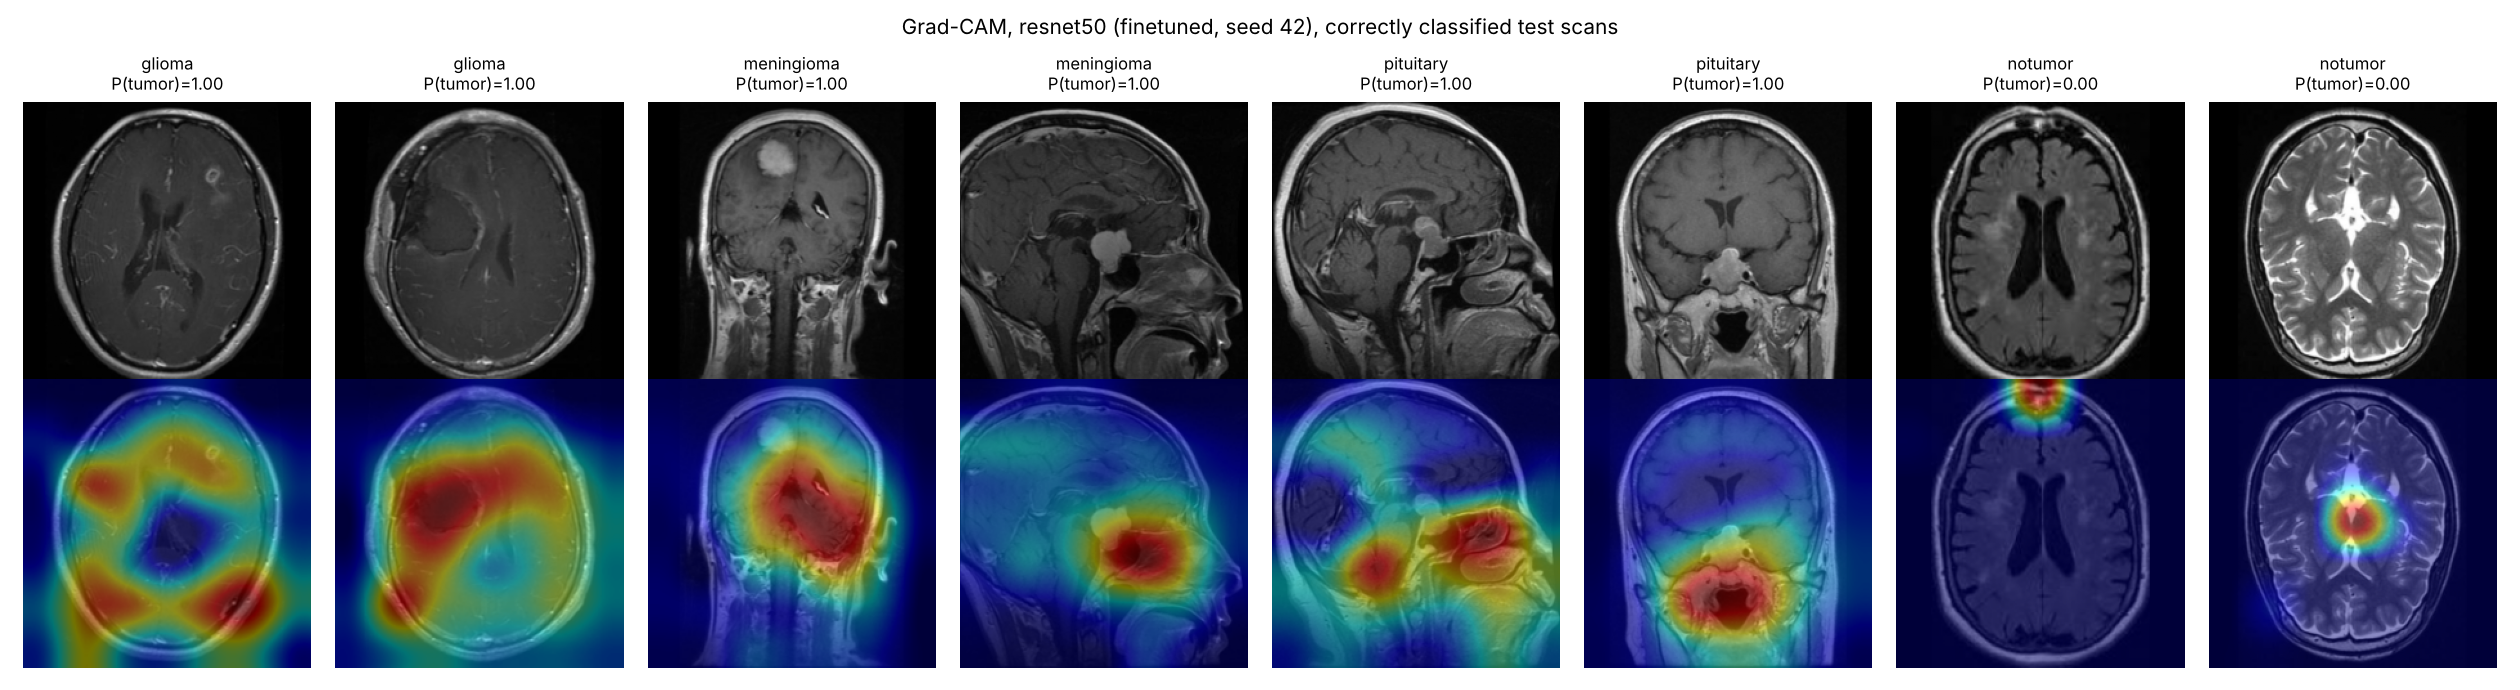

In [9]:
fig_path = config.FIG_DIR / "final_resnet50_gradcam.png"
if RERUN or not fig_path.exists():
    from src.gradcam_figures import gradcam_figure
    gradcam_figure("resnet50")
display(Image(str(fig_path), width=900))